# What Really Matters in Data Jobs?

### 11 comparisons about pay, education and work, based on survey answers from 297 data professionals

Do people who work longer earn more? Do parents choose an 8-hour day more often? Is pay the main reason people like their job?

It is easy to find a difference in survey data. It is harder to know if that difference is real. In this project, we look at pay, education, daily work, job satisfaction and the future of the industry. We also test each comparison, so we can separate strong results from differences that may come from chance.

**Main results:**

- **Two differences are strong.** Data engineers have much less influence on technology choices, and people who work on projects more often are more satisfied.
- **Many differences are weak.** Men, people who work 9-10 hours and people with more experience have higher average or median pay in this sample, but these differences could come from chance.
- **Pay is not the top reason for satisfaction.** People choose job stability and the team most often. Pay comes last.

*Source: Wielka Ankieta Branży Data, Crappy Data.*

## About the data

The data comes from **Wielka Ankieta Branży Data** (Great Data Industry Survey), created by **Crappy Data**. People who work in data roles answered questions about their job, team, tools, pay, well-being and future plans.

- **Size:** 297 people and 7 connected tables. The tables share an `id` column.
- **Scales:** ratings go from 1 to 10.
- **Pay:** the values are in PLN.

**The raw data is not in this repository.** The data rules do not allow publishing it. For this reason, this notebook shows only group results and hides groups with fewer than 5 people.

## How we test the differences

We use three simple tests. Each one gives a **p-value**. A small p-value means that the difference would be unlikely if the groups were really the same. A large p-value means that the difference could easily come from chance.

| Test | When we use it |
|---|---|
| Mann-Whitney U | To compare a number, such as pay, between 2 groups |
| Kruskal-Wallis | To compare a number between more than 2 groups |
| Fisher's exact / chi-square | To compare shares, such as "% who answered yes" |

We use the usual limit of **p < 0.05**. We also do many tests in this project, so one result can look strong just by chance. The final section takes this into account.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

# The raw data stays outside this project folder, so it cannot be uploaded by accident
DATA_DIR = Path("../data")
IMAGE_DIR = Path("images")
MIN_GROUP_SIZE = 5
SOURCE = "Source: Wielka Ankieta Branży Data, Crappy Data."

ACCENT = "#2a78d6"
MUTED = "#c3c2b7"
TEXT = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SURFACE = "#fcfcfb"

files = sorted(DATA_DIR.glob("*.csv"))
df = pd.read_csv(files[0])
for file in files[1:]:
    # validate="1:1" stops the code if one person appears twice
    df = df.merge(pd.read_csv(file), on="id", validate="1:1")

print(f"People: {df.shape[0]}")
print(f"Tables: {len(files)}")

People: 297
Tables: 7


## Prepare the data

The original column names are long questions in Polish. We give short English names to the columns that we use, and we translate the answers.

We do not fill in missing answers. Each calculation uses only the people who answered the question.

In [2]:
column_names = {
    "stanowisko": "position",
    "płeć": "gender",
    "kierunek wykształcenia": "education_field",
    "lata doświadczenia": "total_experience",
    "poziom stanowiska (seniority)": "seniority",
    "ile lat pracujesz na tym stanowisku": "years_in_position",
    "rodzic": "is_parent",
    "jaki jest przybliżony rozkład płci w twoim zespole": "team_gender",
    "jak oceniasz swój zespół pod względem relacji personalnych (atmosfera, współpraca)": "team_relations",
    "jaki procent twojej pracy stanowi programowanie": "programming_score",
    "czy masz wpływ na wybór technologii (tech stacku) w swoim zespole / firmie": "tech_influence",
    "jak często pracujesz w formie projektów": "project_work",
    "w jakiej formie jesteś obecnie zatrudniony/a": "contract",
    "zarobki": "pay",
    "ile godzin dziennie średnio pracujesz": "daily_hours",
    "w jaki stopniu jesteś zadowolona/y ze swojej pracy": "satisfaction",
    "czy obecnie szkolisz się lub rozwijasz swoje umiejętności zawodowe": "training",
    "jak oceniasz przyszłość branży data / it": "industry_future",
}
df = df.rename(columns=column_names)

answer_names = {
    "position": {
        "business analyst": "Business analyst",
        "business intelligence (bi) developer": "BI developer",
        "data analyst": "Data analyst",
        "data engineer": "Data engineer",
        "data scientist": "Data scientist",
        "ml/ai engineer": "ML/AI engineer",
        "analytics engineer": "Analytics engineer",
    },
    "gender": {"kobieta": "women", "mężczyzna": "men"},
    "education_field": {"Informatyczne": "computer science"},
    "team_gender": {
        "w większości męski": "mostly men",
        "w większości żeński": "mostly women",
        "zrównoważony pod względem płci": "balanced",
    },
    "tech_influence": {"tak": "yes", "nie": "no", "trudno powiedzieć": "hard to say"},
    "project_work": {
        "regularnie – większość mojej pracy ma charakter projektowy": "Regularly",
        "częściowo – część zadań to projekty, część bieżące zadania": "Partly",
        "rzadko – głównie bieżące zadania": "Rarely",
        "w ogóle – moja praca nie ma charakteru projektowego": "Not at all",
    },
    "daily_hours": {"8 godzin": "8 hours", "9–10 godzin": "9-10 hours"},
    "training": {"tak, regularnie": "regularly"},
}
for column, names in answer_names.items():
    df[column] = df[column].replace(names)

satisfaction_reasons = {
    "zadowolenie | stabilność zatrudnienia": "Job stability",
    "zadowolenie | zespół i atmosfera": "Team and atmosphere",
    "zadowolenie | work-life balance": "Work-life balance",
    "zadowolenie | zakres obowiązków / ciekawe projekty": "Duties / interesting projects",
    "zadowolenie | przełożony / sposób zarządzania": "Manager / management style",
    "zadowolenie | możliwość rozwoju": "Development opportunities",
    "zadowolenie | wynagrodzenie": "Pay",
}

degree_columns = [
    "wykształcenie__licencjat",
    "wykształcenie__inżynier",
    "wykształcenie__magister",
    "wykształcenie__doktorat",
]
education_level_columns = [column for column in df.columns if column.startswith("wykształcenie__")]

These small functions keep the analysis short, because we repeat the same steps many times.

In [3]:
def mann_whitney_p(group_a, group_b):
    return stats.mannwhitneyu(group_a.dropna(), group_b.dropna()).pvalue


def fisher_p(group_mask, answer_mask):
    return stats.fisher_exact(pd.crosstab(group_mask, answer_mask))[1]


def share_by_position(data, answer_mask):
    table = (
        data.assign(answer=answer_mask)
        .groupby("position")["answer"]
        .agg(people="count", share="mean")
    )
    table["share"] = (table["share"] * 100).round(1)
    return table[table["people"] >= MIN_GROUP_SIZE].sort_values("share")


def draw_bars(ax, values, highlight=None, number_format="{:.1f}"):
    # Direct labels replace the value axis, so the chart needs no grid
    highlight = values.index if highlight is None else highlight
    colors = [ACCENT if label in highlight else MUTED for label in values.index]
    bars = ax.barh(values.index, values.values, color=colors, height=0.72)
    ax.bar_label(bars, [number_format.format(value) for value in values.values], padding=4, color=TEXT, fontsize=10)
    ax.set_xlim(0, values.max() * 1.15)
    ax.xaxis.set_visible(False)
    ax.tick_params(axis="y", length=0, labelcolor=TEXT_SECONDARY, labelsize=10)
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(MUTED)
    ax.set_facecolor(SURFACE)


def finish_figure(fig, title, subtitle, filename):
    fig.patch.set_facecolor(SURFACE)
    fig.tight_layout(rect=(0, 0.05, 1, 0.84))
    fig.text(0.02, 0.94, title, fontsize=13, fontweight="bold", color=TEXT)
    fig.text(0.02, 0.87, subtitle, fontsize=10, color=TEXT_SECONDARY)
    fig.text(0.02, 0.015, SOURCE, fontsize=8, color=TEXT_SECONDARY)
    fig.savefig(IMAGE_DIR / filename, dpi=160, facecolor=SURFACE)
    plt.show()

---
## 1. Who answered the survey?

We start with the people behind the numbers.

In [4]:
position_counts = df["position"].value_counts().rename("people").to_frame()
position_counts = position_counts[position_counts["people"] >= MIN_GROUP_SIZE]
position_counts["share_%"] = (position_counts["people"] / len(df) * 100).round(1)

gender_counts = df["gender"].value_counts().rename("people").to_frame()
gender_counts["share_%"] = (gender_counts["people"] / len(df) * 100).round(1)

display(position_counts)
display(gender_counts)

,people,share_%
position,,
Data analyst,162,54.5
Data scientist,39,13.1
Data engineer,33,11.1
BI developer,26,8.8
Business analyst,20,6.7
ML/AI engineer,13,4.4


,people,share_%
gender,,
women,167,56.2
men,130,43.8


**What we see:** more than half of the people are data analysts (54.5%), and more than half are women (56.2%).

**Why it matters:** people chose to answer this survey, and this mix may be different from the whole industry. For this reason, our results describe the people in this sample.

The analytics engineer group has fewer than 5 people, so we do not show it in the tables and charts.

---
## 2. Pay: three differences that look bigger than they are

Pay is usually the first thing people want to compare. We start with three simple comparisons.

**Important:** the description does not say if pay is before or after tax. B2B pay may also mean something different from employment contract pay. These comparisons do not adjust for contract type, position or seniority.

### Do men earn more than women?

In [5]:
pay_by_gender = df.groupby("gender")["pay"].agg(people="count", mean="mean", median="median").round(0)
gender_pay_p = mann_whitney_p(df.loc[df["gender"] == "men", "pay"], df.loc[df["gender"] == "women", "pay"])

print(f"Difference in means: {pay_by_gender.loc['men', 'mean'] - pay_by_gender.loc['women', 'mean']:.0f} PLN")
print(f"Mann-Whitney p-value: {gender_pay_p:.3f}")
pay_by_gender

Difference in means: 625 PLN
Mann-Whitney p-value: 0.158


,people,mean,median
gender,,,
men,118,9804.0,8500.0
women,149,9179.0,8500.0


**Result:** mean pay is about 625 PLN higher for men, but **the medians are the same** (8,500 PLN). A few high salaries can raise a mean, while the median stays the same. The p-value is large (0.158), so this sample does not show a clear pay gap.

This does not prove that there is no gap. The sample may be too small to find one.

### Do longer hours come with higher pay?

In [6]:
pay_by_hours = (
    df[df["daily_hours"].isin(["8 hours", "9-10 hours"])]
    .groupby("daily_hours")["pay"]
    .agg(people="count", median="median")
)
hours_pay_p = mann_whitney_p(df.loc[df["daily_hours"] == "9-10 hours", "pay"], df.loc[df["daily_hours"] == "8 hours", "pay"])

print(f"Mann-Whitney p-value: {hours_pay_p:.3f}")
pay_by_hours

Mann-Whitney p-value: 0.143


,people,median
daily_hours,,
8 hours,164,8200.0
9-10 hours,30,9600.0


**Result:** the median is 9,600 PLN for 9-10 hours and 8,200 PLN for 8 hours. This looks like a big difference, but only 30 people are in the longer-hours group, and the p-value is large (0.143).

### Does total experience matter when people are at the same level?

To make a fair comparison, we look only at mid / regular people who have been in their position for 1-2 years. Then we compare people with more or less total experience.

In [7]:
same_stage = df[
    (df["years_in_position"] == "1-2 lata")
    & (df["seniority"] == "mid / regular")
    & df["total_experience"].notna()
].copy()
same_stage["experience_group"] = (
    same_stage["total_experience"]
    .isin(["do 2 lat", "3–5 lat"])
    .map({True: "up to 5 years", False: "over 5 years"})
)

pay_by_experience = same_stage.groupby("experience_group")["pay"].agg(people="count", mean="mean", median="median").round(0)
experience_pay_p = mann_whitney_p(
    same_stage.loc[same_stage["experience_group"] == "over 5 years", "pay"],
    same_stage.loc[same_stage["experience_group"] == "up to 5 years", "pay"],
)

print(f"Mann-Whitney p-value: {experience_pay_p:.3f}")
pay_by_experience

Mann-Whitney p-value: 0.403


,people,mean,median
experience_group,,,
over 5 years,35,8791.0,8000.0
up to 5 years,22,8335.0,7075.0


**Result:** people with over 5 years earn more on average (8,791 PLN compared with 8,335 PLN), but the groups are small (35 and 22 people), and the p-value is large (0.403).

**What we learned about pay:** all three differences point in the expected direction, but none of them passes the test. Next, we look for stronger differences between positions, starting with education.

---
## 3. Education: two questions, two different answers

"Education" can mean two things: the **level** (does the person have a degree?) and the **field** (what did the person study?). These give different results.

- **Degree:** licencjat (bachelor), inżynier (engineer), magister (master) or doktorat (PhD).
- **Field:** the survey data keeps only the first field from each person's list, so the computer science shares may be too low.

In [8]:
known_level = df[df[education_level_columns].sum(axis=1) > 0]
has_degree = known_level[degree_columns].sum(axis=1) > 0
degree_share = share_by_position(known_level, has_degree)

known_field = df[df["education_field"].notna()]
is_computer_science = known_field["education_field"].eq("computer science")
computer_science_share = share_by_position(known_field, is_computer_science)

degree_p = fisher_p(known_level["position"].eq("Data engineer"), has_degree)
field_p = fisher_p(known_field["position"].eq("ML/AI engineer"), is_computer_science)

print(f"Degree, data engineers vs everyone else: p = {degree_p:.3f}")
print(f"Computer science, ML/AI engineers vs everyone else: p = {field_p:.3f}")

education = degree_share.rename(columns={"people": "people_level", "share": "degree_%"}).join(
    computer_science_share.rename(columns={"people": "people_field", "share": "computer_science_%"})
)
education

Degree, data engineers vs everyone else: p = 0.047
Computer science, ML/AI engineers vs everyone else: p = 0.082


,people_level,degree_%,people_field,computer_science_%
position,,,,
Data engineer,32,81.2,33,24.2
BI developer,26,88.5,25,36.0
Data analyst,161,91.3,156,19.9
ML/AI engineer,13,92.3,13,46.2
Business analyst,20,95.0,19,10.5
Data scientist,39,97.4,38,23.7


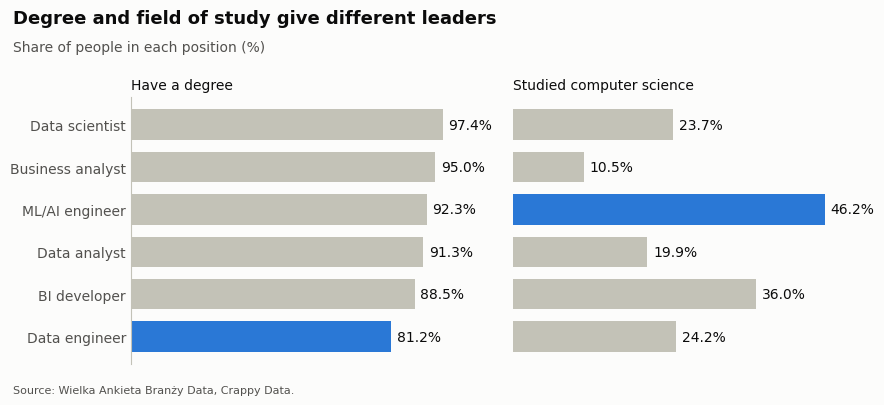

In [9]:
fig, (ax_level, ax_field) = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

draw_bars(ax_level, education["degree_%"], highlight=["Data engineer"], number_format="{:.1f}%")
draw_bars(ax_field, education["computer_science_%"], highlight=["ML/AI engineer"], number_format="{:.1f}%")
ax_field.spines["left"].set_visible(False)
ax_level.set_title("Have a degree", loc="left", fontsize=10, color=TEXT)
ax_field.set_title("Studied computer science", loc="left", fontsize=10, color=TEXT)

finish_figure(
    fig,
    "Degree and field of study give different leaders",
    "Share of people in each position (%)",
    "education.png",
)

**Result:**

- **Level:** data engineers have the lowest share of people with a degree (81.2%, compared with 92.4% for everyone else). The p-value is 0.047, so the evidence is only moderate.
- **Field:** ML/AI engineers have the highest share of computer science graduates (46.2%, compared with 21.8% for everyone else). This group has only 13 people, and the p-value is 0.082.

**What we learned:** a degree is very common in every position, but a computer science degree is not. In most positions, fewer than 1 in 4 people studied it. Data work is open to people from many fields.

Next, we move from what people studied to what they do at work.

---
## 4. Daily work: one clear gap between positions

### Who influences the choice of technology?

We count people who answered "yes". The group also includes people who answered "no" or "hard to say".

Data engineers vs everyone else: p = 0.004


,people,share
position,,
Data engineer,33,9.1
BI developer,25,28.0
Data analyst,160,28.1
Business analyst,19,31.6
Data scientist,39,48.7
ML/AI engineer,13,61.5


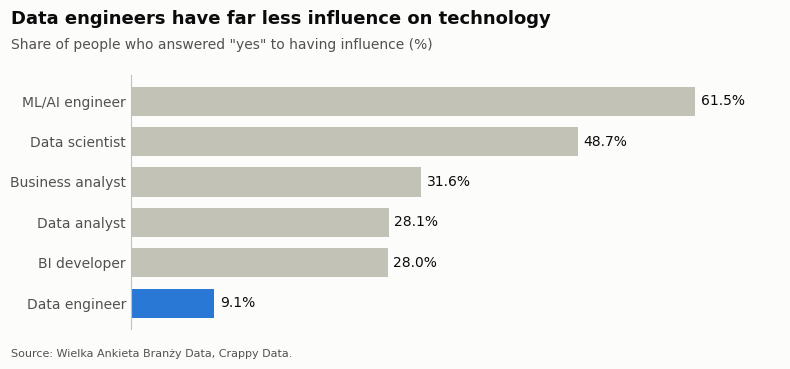

In [10]:
known_influence = df[df["tech_influence"].notna()]
has_influence = known_influence["tech_influence"].eq("yes")
influence_share = share_by_position(known_influence, has_influence)
influence_p = fisher_p(known_influence["position"].eq("Data engineer"), has_influence)

print(f"Data engineers vs everyone else: p = {influence_p:.3f}")
display(influence_share)

fig, ax = plt.subplots(figsize=(8, 3.6))
draw_bars(ax, influence_share["share"], highlight=["Data engineer"], number_format="{:.1f}%")
finish_figure(
    fig,
    "Data engineers have far less influence on technology",
    'Share of people who answered "yes" to having influence (%)',
    "tech_influence.png",
)

**Result:** only 9.1% of data engineers say that they influence technology choices, compared with 33.5% of everyone else. **This is one of the strongest results in the project** (p = 0.004).

The survey does not explain why. One possible reason is that large companies often decide on data platforms centrally, but we cannot test this idea with these data.

### Do B2B workers program more?

The survey column is called "percent", but its values are a score from 1 to 10. We use it as a scale, where a higher value means more programming.

In [11]:
known_contract = df[df["contract"].notna()].copy()
known_contract["contract_group"] = known_contract["contract"].str.startswith("b2b").map({True: "B2B", False: "other contracts"})

programming = known_contract.groupby("contract_group")["programming_score"].agg(people="count", mean="mean", median="median").round(2)
programming_p = mann_whitney_p(
    known_contract.loc[known_contract["contract_group"] == "B2B", "programming_score"],
    known_contract.loc[known_contract["contract_group"] == "other contracts", "programming_score"],
)

print(f"Mann-Whitney p-value: {programming_p:.3f}")
programming

Mann-Whitney p-value: 0.370


,people,mean,median
contract_group,,,
B2B,39,5.69,6.0
other contracts,253,5.27,6.0


**Result:** the mean score is a little higher for B2B (5.69 compared with 5.27), but the medians are the same (6), and the p-value is large (0.370). We do not see a clear difference.

### Do parents work a standard day more often?

The groups have different sizes, so we compare shares and not counts.

In [12]:
known_hours = df[df["daily_hours"].notna()].copy()
known_hours["works_8_hours"] = known_hours["daily_hours"].eq("8 hours")

eight_hours = known_hours.groupby(known_hours["is_parent"].map({True: "parents", False: "no children"}))["works_8_hours"].agg(people="count", share="mean")
eight_hours["share"] = (eight_hours["share"] * 100).round(1)
parent_p = stats.chi2_contingency(pd.crosstab(known_hours["is_parent"], known_hours["works_8_hours"])).pvalue

print(f"Chi-square p-value: {parent_p:.3f}")
eight_hours

Chi-square p-value: 0.071


,people,share
is_parent,,
no children,210,57.6
parents,83,69.9


**Result:** 69.9% of parents work 8 hours a day, compared with 57.6% of people without children. The p-value is 0.071, so this is a hint and not strong evidence.

**What we learned about daily work:** position matters more clearly here than contract type or being a parent. Next, we ask how people feel about their work.

---
## 5. Job satisfaction: what people value

### What are people satisfied with?

People could choose more than one reason.

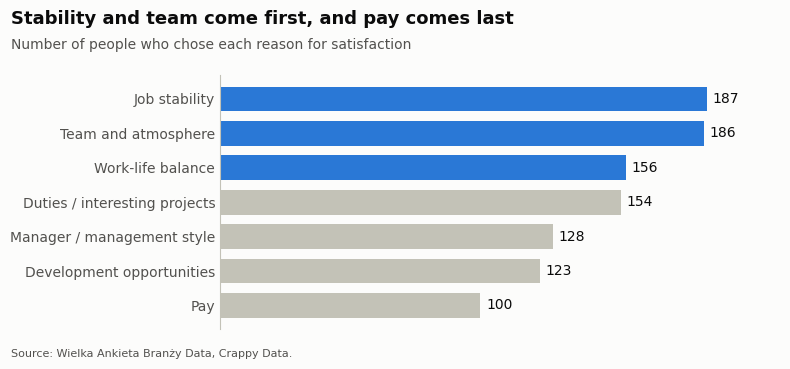

In [13]:
reason_counts = df[list(satisfaction_reasons)].sum().rename(index=satisfaction_reasons).sort_values()
top_three = reason_counts.index[-3:]

fig, ax = plt.subplots(figsize=(8, 3.6))
draw_bars(ax, reason_counts, highlight=top_three, number_format="{:.0f}")
finish_figure(
    fig,
    "Stability and team come first, and pay comes last",
    "Number of people who chose each reason for satisfaction",
    "satisfaction_reasons.png",
)

**Result:** the top three reasons are **job stability (187), team and atmosphere (186) and work-life balance (156)**. Duties and interesting projects are very close in fourth place (154). **Pay is last (100).**

This does not mean that pay is not important. It may only mean that fewer people are happy with their pay.

### Does project work go together with satisfaction?

"Duties and interesting projects" is a popular reason, so we check the type of work next.

Mean, regularly or partly: 7.04
Mean, rarely or not at all: 5.93
Mann-Whitney p-value: 0.0007


,people,mean
project_work,,
Regularly,110,7.07
Partly,124,7.01
Rarely,38,5.92
Not at all,20,5.95


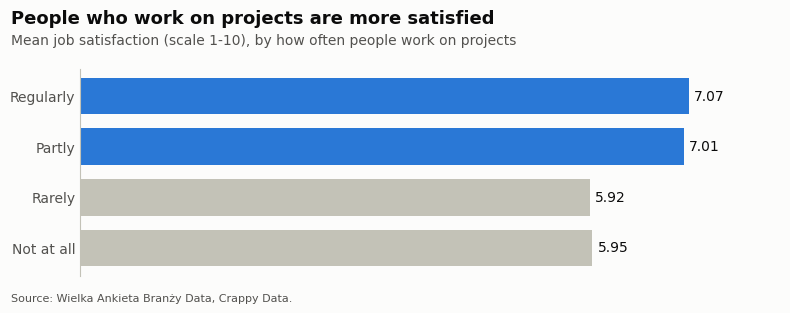

In [14]:
project_order = ["Regularly", "Partly", "Rarely", "Not at all"]
satisfaction_by_projects = df.groupby("project_work")["satisfaction"].agg(people="count", mean="mean").loc[project_order].round(2)

more_projects = df["project_work"].isin(["Regularly", "Partly"])
less_projects = df["project_work"].isin(["Rarely", "Not at all"])
more_vs_less_p = mann_whitney_p(df.loc[more_projects, "satisfaction"], df.loc[less_projects, "satisfaction"])

print(f"Mean, regularly or partly: {df.loc[more_projects, 'satisfaction'].mean():.2f}")
print(f"Mean, rarely or not at all: {df.loc[less_projects, 'satisfaction'].mean():.2f}")
print(f"Mann-Whitney p-value: {more_vs_less_p:.4f}")
display(satisfaction_by_projects)

fig, ax = plt.subplots(figsize=(8, 3))
draw_bars(ax, satisfaction_by_projects["mean"].iloc[::-1], highlight=["Regularly", "Partly"], number_format="{:.2f}")
finish_figure(
    fig,
    "People who work on projects are more satisfied",
    "Mean job satisfaction (scale 1-10), by how often people work on projects",
    "project_satisfaction.png",
)

**Result:** people who work on projects regularly or partly have a mean satisfaction of 7.04. People who work on projects rarely or never have a mean of 5.93. **This is the strongest result in the project** (p < 0.001).

There is almost no difference between "regularly" and "partly" (7.07 and 7.01). The main gap is between having some project work and having very little.

This does not show that projects make people happier. For example, more satisfying jobs may simply include more project work.

### Does the gender mix of a team change how people rate team relations?

In [15]:
mostly_one_gender = df[df["team_gender"].isin(["mostly men", "mostly women"])]
team_relations = (
    mostly_one_gender.groupby(["gender", "team_gender"])["team_relations"]
    .agg(people="count", mean="mean")
    .sort_values("mean", ascending=False)
    .round(2)
)
relation_groups = [group["team_relations"].dropna() for _, group in mostly_one_gender.groupby(["gender", "team_gender"])]
relations_p = stats.kruskal(*relation_groups).pvalue

print(f"Kruskal-Wallis p-value: {relations_p:.3f}")
team_relations

Kruskal-Wallis p-value: 0.819


people  mean
gender team_gender               
women  mostly women      43  7.95
men    mostly women      13  7.85
       mostly men        67  7.81
women  mostly men        62  7.69

**Result:** all four groups give almost the same rating (from 7.69 to 7.95), and the p-value is large (0.819). We see no sign that team gender mix changes this rating.

Satisfaction describes the present. In the final step, we look at how people see the future.

---
## 6. The future of the industry

In [16]:
known_training = df[df["training"].notna()].copy()
known_training["training_group"] = known_training["training"].eq("regularly").map({True: "regular training", False: "everyone else"})

future_by_training = known_training.groupby("training_group")["industry_future"].agg(people="count", mean="mean", median="median").round(2)
training_p = mann_whitney_p(
    known_training.loc[known_training["training_group"] == "regular training", "industry_future"],
    known_training.loc[known_training["training_group"] == "everyone else", "industry_future"],
)

print(f"Mean rating, all people: {df['industry_future'].mean():.2f} ({df['industry_future'].count()} people)")
print(f"Mann-Whitney p-value: {training_p:.3f}")
future_by_training

Mean rating, all people: 6.29 (288 people)
Mann-Whitney p-value: 0.326


,people,mean,median
training_group,,,
everyone else,130,6.18,6.0
regular training,158,6.38,7.0


**Result:** the mean rating is **6.29 out of 10**, so people are moderately positive. People who train regularly give only a slightly higher rating (6.38 compared with 6.18), and the p-value is large (0.326).

---
## Conclusions

We tested 11 comparisons. With this many tests, a stricter limit is useful. The Bonferroni correction divides 0.05 by the number of tests, which gives **p < 0.0045**.

| Topic | Comparison | Result | p-value | Evidence |
|---|---|---|---|---|
| Satisfaction | More vs less project work | 7.04 vs 5.93 | < 0.001 | **Strong** |
| Daily work | Influence on technology: data engineers vs others | 9.1% vs 33.5% | 0.004 | **Strong** |
| Education | Degree: data engineers vs others | 81.2% vs 92.4% | 0.047 | Moderate |
| Daily work | 8-hour day: parents vs others | 69.9% vs 57.6% | 0.071 | Weak |
| Education | Computer science: ML/AI engineers vs others | 46.2% vs 21.8% | 0.082 | Weak |
| Pay | Median at 9-10 hours vs 8 hours | 9,600 vs 8,200 PLN | 0.143 | Weak |
| Pay | Mean: men vs women | 9,804 vs 9,179 PLN | 0.158 | Weak |
| Future | Future rating: regular training vs others | 6.38 vs 6.18 | 0.326 | Weak |
| Daily work | Programming score: B2B vs others | 5.69 vs 5.27 | 0.370 | Weak |
| Pay | Mean: over 5 vs up to 5 years of experience | 8,791 vs 8,335 PLN | 0.403 | Weak |
| Team | Team relations by gender and team mix | 7.69 to 7.95 | 0.819 | None |

### Take-home messages

1. **Check differences before you believe them.** Only 2 of 11 comparisons pass the stricter limit.
2. **Look at the median as well as the mean.** Men have a higher mean pay here, but the medians are the same.
3. **Do not assume that a data job needs a computer science degree.** In most positions, fewer than 1 in 4 people studied it.
4. **If you want influence on technology, ask about it in interviews.** Data engineers report the least influence, so the job title alone does not tell you how much freedom you will have.
5. **Look beyond pay when you choose a job.** People mention stability, team and work-life balance more often, and people with some project work are more satisfied.

### Limits of this analysis

- **Sample:** people chose to answer, so the results may not describe the whole industry.
- **Cause and effect:** one survey shows connections, not causes.
- **Simple comparisons:** most comparisons do not adjust for other factors, such as position or seniority.
- **Pay:** we do not know if pay is before or after tax, and contract types may not be directly comparable.
- **Education field:** the data keeps only the first field from each person's list.
- **Possible next step:** use regression to compare pay and satisfaction while taking other factors into account.

*Source: Wielka Ankieta Branży Data, Crappy Data.*